In [1]:
# NIM: 202431135 - BAGAS SATYA ANINDITHA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Library berhasil di-import!")

Library berhasil di-import!


In [2]:
# NIM: 202431135 - BAGAS SATYA ANINDITHA
# Load file dataset counter strike 2
df = pd.read_csv('03_counter_strike_2.csv')

# Tampilkan 5 baris pertama
print("--- 5 Baris Pertama Dataset ---")
display(df.head())

# Cek struktur kolom dan tipe data
print("\n--- Informasi Tipe Data ---")
df.info()

# Cek apakah ada data yang kosong (null/missing values)
print("\n--- Jumlah Missing Values per Kolom ---")
print(df.isnull().sum())

--- 5 Baris Pertama Dataset ---


,time_left,ct_score,t_score,map,bomb_planted,ct_health,t_health,ct_armor,t_armor,ct_money,t_money,ct_helmets,t_helmets,round_winner
0,175.00,0.0,0.0,de_dust2,False,500.0,500.0,0.0,0.0,4000.0,4000.0,0.0,0.0,CT
1,156.03,0.0,0.0,de_dust2,False,500.0,500.0,400.0,300.0,600.0,650.0,0.0,0.0,CT
2,96.03,0.0,0.0,de_dust2,False,391.0,400.0,294.0,200.0,750.0,500.0,0.0,0.0,CT
3,76.03,0.0,0.0,de_dust2,False,391.0,400.0,294.0,200.0,750.0,500.0,0.0,0.0,CT
4,174.97,1.0,0.0,de_dust2,False,500.0,500.0,192.0,0.0,18350.0,10750.0,0.0,0.0,CT



--- Informasi Tipe Data ---
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   time_left     2000 non-null   float64
 1   ct_score      2000 non-null   float64
 2   t_score       2000 non-null   float64
 3   map           2000 non-null   str    
 4   bomb_planted  2000 non-null   bool   
 5   ct_health     2000 non-null   float64
 6   t_health      2000 non-null   float64
 7   ct_armor      2000 non-null   float64
 8   t_armor       2000 non-null   float64
 9   ct_money      2000 non-null   float64
 10  t_money       2000 non-null   float64
 11  ct_helmets    2000 non-null   float64
 12  t_helmets     2000 non-null   float64
 13  round_winner  2000 non-null   str    
dtypes: bool(1), float64(11), str(2)
memory usage: 224.8 KB

--- Jumlah Missing Values per Kolom ---
time_left       0
ct_score        0
t_score         0
map             0
bomb_planted  

In [3]:
# NIM: 202431135 - BAGAS SATYA ANINDITHA
# Encoding fitur kategorikal & boolean
le = LabelEncoder()
df_processed = df.copy()

df_processed['map'] = le.fit_transform(df_processed['map'])
df_processed['bomb_planted'] = df_processed['bomb_planted'].astype(int)
df_processed['round_winner'] = le.fit_transform(df_processed['round_winner']) # CT/T menjadi 0/1

# Pemisahan Fitur (X) dan Target (y)
X = df_processed.drop(columns=['round_winner'])
y = df_processed['round_winner']

# Split Data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Feature Scaling (Wajib untuk KNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data Preprocessing selesai! Data siap dilatih.")

Data Preprocessing selesai! Data siap dilatih.


In [6]:
# NIM: 202431135 - BAGAS SATYA ANINDITHA
# Inisialisasi dan Latih Model KNN (K=5)
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

# Prediksi
y_pred_knn = knn_model.predict(X_test_scaled)

# Evaluasi KNN
acc_knn = accuracy_score(y_test, y_pred_knn)
print(f"--- EVALUASI K-NEAREST NEIGHBORS (KNN) ---")
print(f"Akurasi KNN: {acc_knn * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_knn))

--- EVALUASI K-NEAREST NEIGHBORS (KNN) ---
Akurasi KNN: 83.25%

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.79      0.79       156
           1       0.87      0.86      0.86       244

    accuracy                           0.83       400
   macro avg       0.82      0.83      0.82       400
weighted avg       0.83      0.83      0.83       400



In [8]:
# NIM: 202431135 - BAGAS SATYA ANINDITHA
# Inisialisasi dan Latih Model Naive Bayes
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)

# Prediksi
y_pred_nb = nb_model.predict(X_test_scaled)

# Evaluasi Naive Bayes
acc_nb = accuracy_score(y_test, y_pred_nb)
print(f"--- EVALUASI NAIVE BAYES (GAUSSIAN NB) ---")
print(f"Akurasi Naive Bayes: {acc_nb * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_nb))

--- EVALUASI NAIVE BAYES (GAUSSIAN NB) ---
Akurasi Naive Bayes: 72.50%

Classification Report:
              precision    recall  f1-score   support

           0       0.63      0.71      0.67       156
           1       0.80      0.73      0.76       244

    accuracy                           0.72       400
   macro avg       0.71      0.72      0.72       400
weighted avg       0.73      0.72      0.73       400



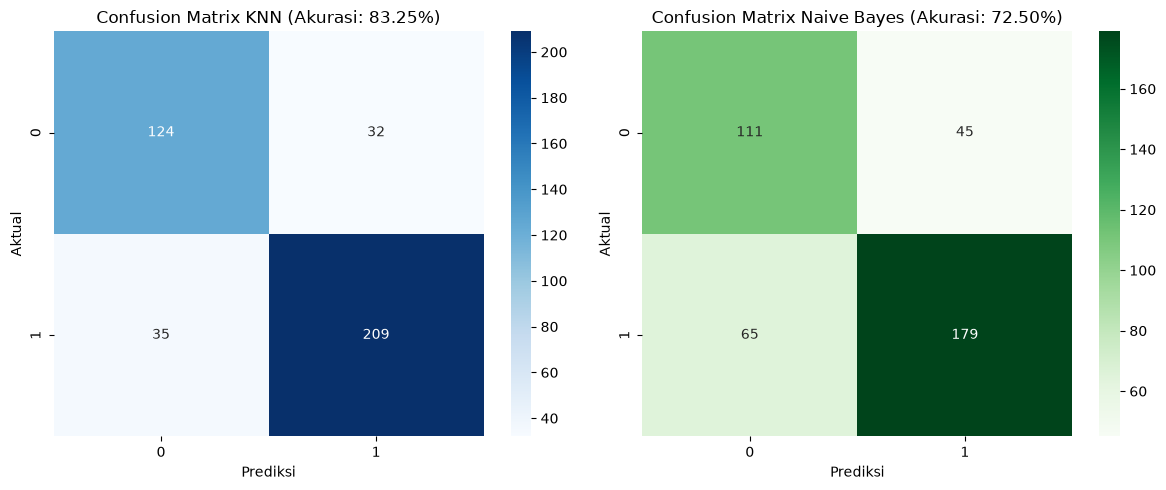

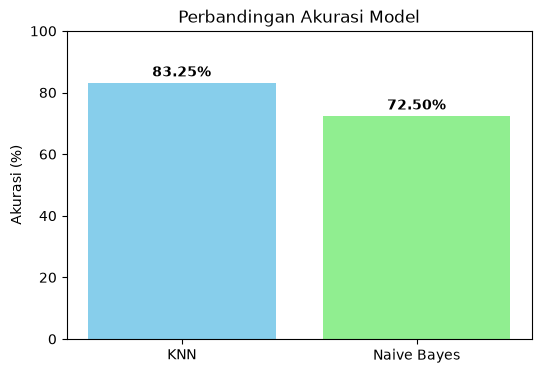

In [9]:
# NIM: 202431135 - BAGAS SATYA ANINDITHA
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion Matrix KNN
sns.heatmap(confusion_matrix(y_test, y_pred_knn), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title(f'Confusion Matrix KNN (Akurasi: {acc_knn*100:.2f}%)')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

# Confusion Matrix Naive Bayes
sns.heatmap(confusion_matrix(y_test, y_pred_nb), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title(f'Confusion Matrix Naive Bayes (Akurasi: {acc_nb*100:.2f}%)')
axes[1].set_xlabel('Prediksi')
axes[1].set_ylabel('Aktual')

plt.tight_layout()
plt.show()

# Grafik Perbandingan Akurasi
plt.figure(figsize=(6, 4))
models = ['KNN', 'Naive Bayes']
accuracies = [acc_knn * 100, acc_nb * 100]
plt.bar(models, accuracies, color=['skyblue', 'lightgreen'])
plt.ylabel('Akurasi (%)')
plt.title('Perbandingan Akurasi Model')
plt.ylim(0, 100)
for i, v in enumerate(accuracies):
    plt.text(i, v + 2, f"{v:.2f}%", ha='center', fontweight='bold')
plt.show()